In [1]:
import pandas as pd
import matplotlib.pyplot as plt

print("Sales Data Analysis Project Started!")
print("Python and libraries are ready")

Sales Data Analysis Project Started!
Python and libraries are ready


In [5]:
df = pd.read_csv("/content/archive.zip")
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [7]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape: (1000, 17)

Column Names:
Index(['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender',
       'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date',
       'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income',
       'Rating'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   10

In [8]:
df.isnull().sum()

,0
Invoice ID,0
Branch,0
City,0
Customer type,0
Gender,0
Product line,0
Unit price,0
Quantity,0
Tax 5%,0
Total,0


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
# Remove duplicate rows
df = df.drop_duplicates()

print("Dataset after removing duplicates:")
print("Rows and Columns:", df.shape)

Dataset after removing duplicates:
Rows and Columns: (1000, 17)


In [11]:
# Check missing values
print(df.isnull().sum())

Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64


In [12]:
df["Date"] = pd.to_datetime(df["Date"])

print(df["Date"].dtype)

datetime64[ns]


In [13]:
# Calculate total sales
total_sales = df["Total"].sum()

print("Total Sales:", total_sales)

Total Sales: 322966.749


In [14]:
# Sales by product category
product_sales = df.groupby("Product line")["Total"].sum()

print(product_sales.sort_values(ascending = False))

Product line
Food and beverages        56144.8440
Sports and travel         55122.8265
Electronic accessories    54337.5315
Fashion accessories       54305.8950
Home and lifestyle        53861.9130
Health and beauty         49193.7390
Name: Total, dtype: float64


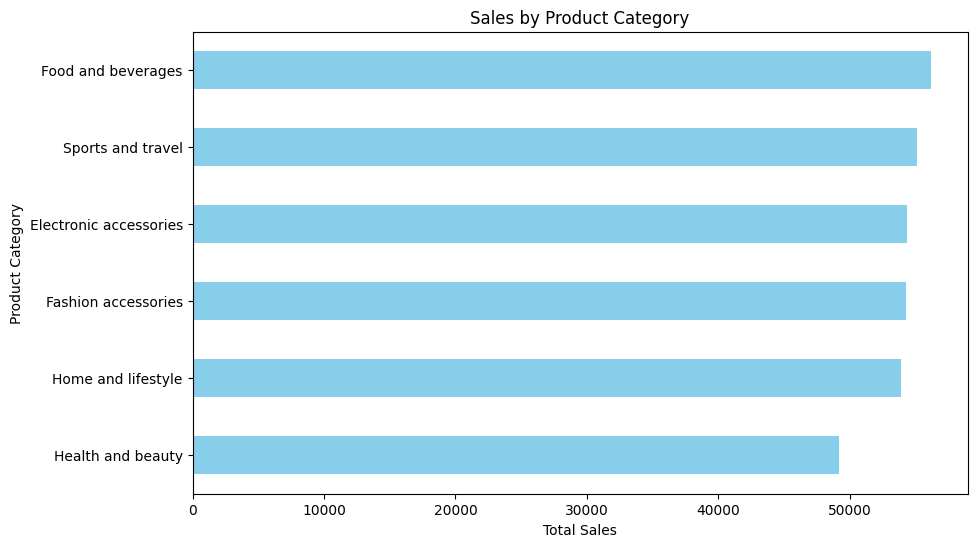

In [16]:
product_sales.sort_values().plot(
    kind="barh",
    figsize=(10,6),
    color="skyblue"
)
plt.title("Sales by Product Category")
plt.xlabel("Total Sales")
plt.ylabel("Product Category")
plt.show()

In [17]:
city_sales = df.groupby("City")["Total"].sum()

print(city_sales.sort_values(ascending = False))

City
Naypyitaw    110568.7065
Yangon       106200.3705
Mandalay     106197.6720
Name: Total, dtype: float64


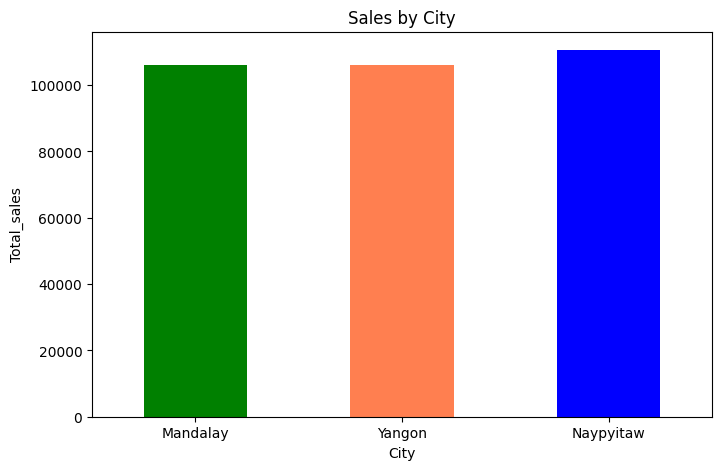

In [19]:
city_sales.sort_values().plot(
    kind="bar",
    figsize=(8,5),
    color=["green","coral","blue"]
)
plt.title("Sales by City")
plt.xlabel("City")
plt.ylabel("Total_sales")
plt.xticks(rotation=0)
plt.show()

In [20]:
payment_counts = df["Payment"].value_counts()

print(payment_counts)

Payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64


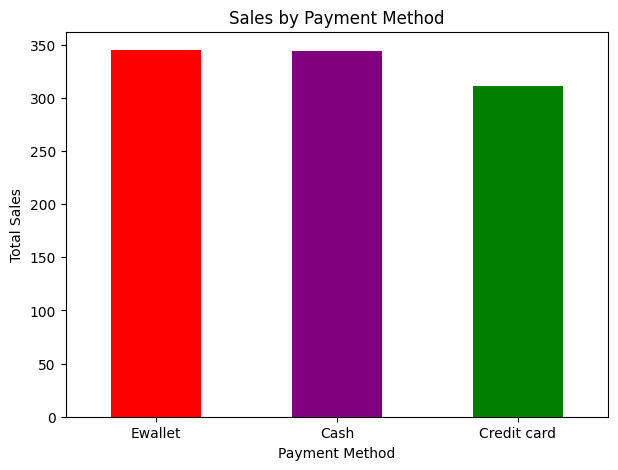

In [27]:
import importlib
import matplotlib.pyplot as plt
importlib.reload(plt)

payment_counts.plot(
    kind="bar",
    figsize=(7,5),
    color=["red","purple","green"]
)
plt.title("Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.show()

In [22]:
df["Month"] = df["Date"].dt.month

monthly_sales = df.groupby("Month")["Total"].sum()

print(monthly_sales)

Month
1    116291.868
2     97219.374
3    109455.507
Name: Total, dtype: float64


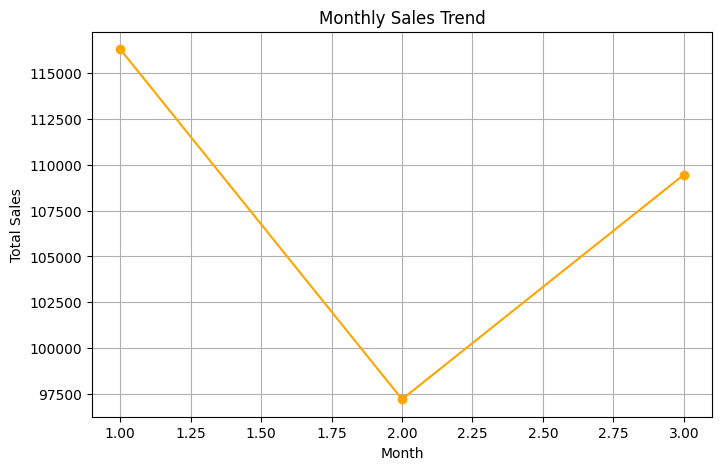

In [26]:
import importlib
import matplotlib.pyplot as plt
importlib.reload(plt)

monthly_sales.plot(
    kind="line",
    marker="o",
    figsize=(8,5),
    color="orange"
)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(True)
plt.show()

In [28]:
quantity_analysis = df.groupby("Product line")["Quantity"].sum()

print(quantity_analysis.sort_values(ascending=False))

Product line
Electronic accessories    971
Food and beverages        952
Sports and travel         920
Home and lifestyle        911
Fashion accessories       902
Health and beauty         854
Name: Quantity, dtype: int64


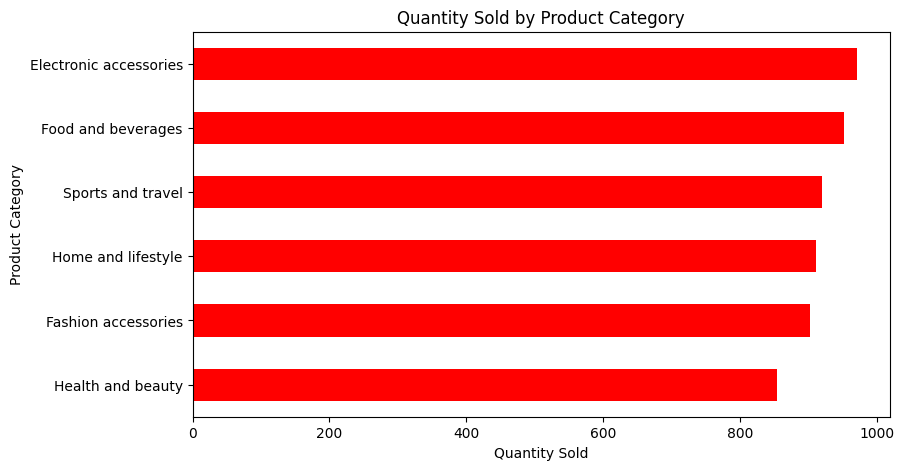

In [31]:
quantity_analysis.sort_values().plot(
    kind="barh",
    figsize=(9,5),
    color="red"
)
plt.title("Quantity Sold by Product Category")
plt.xlabel("Quantity Sold")
plt.ylabel("Product Category")
plt.show()


## **Supermarket Sales Data Analysis**

**Project Overview**

Analyzed supermarket sales data using python, Pandas, and Matplotlib to identify sales trends, customer behavior, and business performance.

**Analysis Performed**


* Data cleaning and duplicate removal
* Missing values inspection
* Sales analysis by product category
* City_wise sales analyst
* Payment method analysis
* Monthly sales trend analysis
* Customer rating analysis
* Product quantity analysis

**Key Findings**



*  Naypyitaw had the highest total sales among the three cities.
*  Yangon had the lowest total sales, but differences between cities were relatively small.
* January had the highest monthly sales.
* February sales decreased significantly.
March sales recovered compared ti February.

**Tools Used**

Python, Pandas, Matplotlib, Google Colab

**Conclusion**

This analysis helps understand sales performance, customer preferences, and monthly trends. These insights can support business decisions related to inventory, marketing, and sales strategies.





